In [1]:
import os
import copy
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms
from torchvision import models
from torch.utils.data import DataLoader

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import seaborn as sns

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("="*50)
print("PyTorch Version :", torch.__version__)
print("Device :", device)

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
    print("CUDA Version :", torch.version.cuda)

print("="*50)

PyTorch Version : 2.6.0+cu124
Device : cuda
GPU : NVIDIA GeForce GTX 1650
CUDA Version : 12.4


In [3]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [5]:
train_dataset = torchvision.datasets.CIFAR10(
    root="./datasets",
    train=True,
    download=False,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./datasets",
    train=False,
    download=False,
    transform=transform
)

print("Training Images :", len(train_dataset))

print("Testing Images  :", len(test_dataset))

Training Images : 50000
Testing Images  : 10000


In [35]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
    
)

In [36]:
classes = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

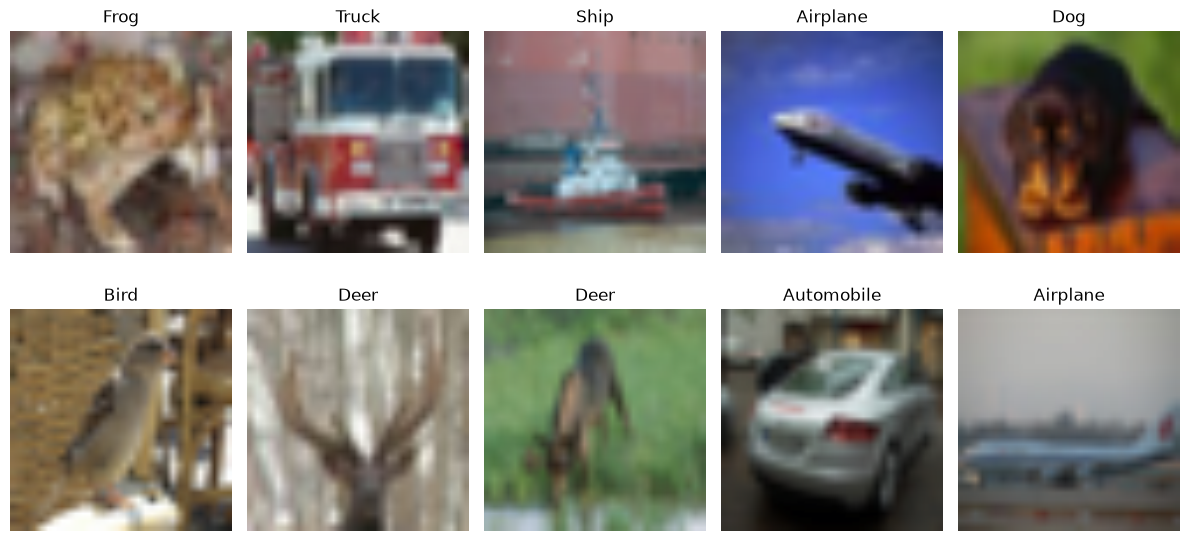

In [37]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(12,6))

for i in range(10):

    plt.subplot(2,5,i+1)

    img = images[i].permute(1,2,0).numpy()

    img = img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])

    img = np.clip(img,0,1)

    plt.imshow(img)

    plt.title(classes[labels[i]])

    plt.axis("off")

plt.tight_layout()


plt.show()

In [38]:
model = models.vit_b_16(
    weights=models.ViT_B_16_Weights.IMAGENET1K_V1
)

model = model.to(device)

print(model)

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [39]:
for param in model.parameters():
    param.requires_grad = False

In [40]:
for param in model.encoder.layers[-1].parameters():
    param.requires_grad = True

In [41]:
model.heads.head = nn.Linear(
    model.heads.head.in_features,
    10
)

model = model.to(device)

In [42]:
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())

print(f"Trainable Parameters : {trainable:,}")
print(f"Total Parameters     : {total:,}")

Trainable Parameters : 7,095,562
Total Parameters     : 85,806,346


In [43]:
criterion = nn.CrossEntropyLoss()

In [44]:
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4
)

In [45]:
def train(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [46]:
def test(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)

            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [47]:
os.makedirs("./models", exist_ok=True)

In [48]:
epochs = 10

train_losses = []
test_losses = []

train_accs = []
test_accs = []

best_acc = 0.0
best_epoch = 0

best_train_loss = 0
best_test_loss = 0

best_train_acc = 0
best_test_acc = 0

for epoch in range(epochs):

    print(f"\nEpoch {epoch+1}/{epochs}")

    train_loss, train_acc = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    test_loss, test_acc = test(
        model,
        test_loader,
        criterion
    )

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_accs.append(train_acc)
    test_accs.append(test_acc)

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.2f}%")

    print(f"Test Loss : {test_loss:.4f}")
    print(f"Test Accuracy : {test_acc:.2f}%")

    if test_acc > best_acc:

        best_acc = test_acc
        best_epoch = epoch + 1

        best_train_loss = train_loss
        best_test_loss = test_loss

        best_train_acc = train_acc
        best_test_acc = test_acc

        torch.save(
            model.state_dict(),
            "./models/best_vit_b16.pth"
        )

        print("Best Model Saved")


Epoch 1/10


  0%|          | 0/1563 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

Train Loss : 0.1806
Train Accuracy : 94.37%
Test Loss : 0.1225
Test Accuracy : 95.91%
Best Model Saved

Epoch 2/10


  0%|          | 0/1563 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

... (21 outputs left out)

Train Loss : 0.0083
Train Accuracy : 99.75%
Test Loss : 0.1843
Test Accuracy : 96.23%

Epoch 10/10


  0%|          | 0/1563 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

Train Loss : 0.0059
Train Accuracy : 99.82%
Test Loss : 0.2045
Test Accuracy : 95.94%


In [49]:
model.load_state_dict(
    torch.load(
        "./models/best_vit_b16.pth",
        map_location=device
    )
)

model = model.to(device)

model.eval()

print("Best ViT Model Loaded Successfully!")

Best ViT Model Loaded Successfully!


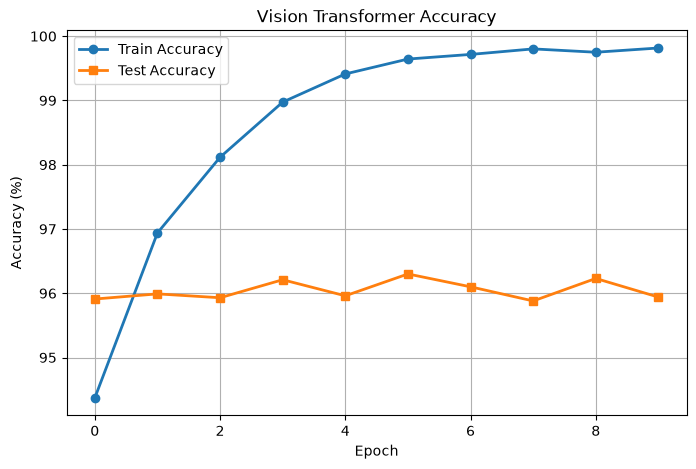

In [50]:
plt.figure(figsize=(8,5))

plt.plot(train_accs,
         marker='o',
         linewidth=2,
         label='Train Accuracy')

plt.plot(test_accs,
         marker='s',
         linewidth=2,
         label='Test Accuracy')

plt.title("Vision Transformer Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.grid(True)
plt.legend()

plt.show()

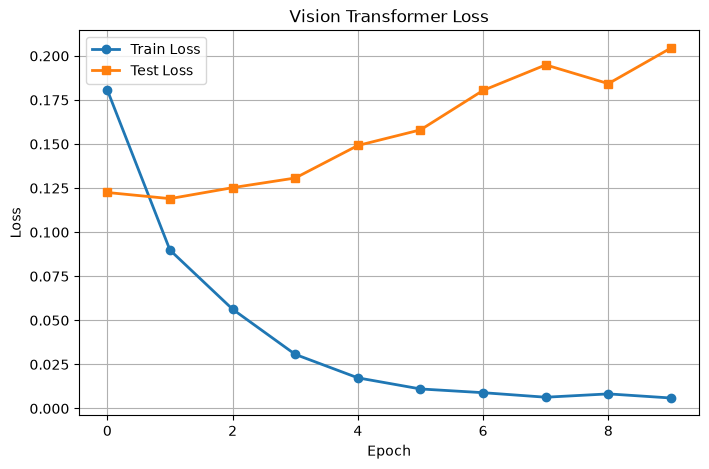

In [51]:
plt.figure(figsize=(8,5))

plt.plot(train_losses,
         marker='o',
         linewidth=2,
         label='Train Loss')

plt.plot(test_losses,
         marker='s',
         linewidth=2,
         label='Test Loss')

plt.title("Vision Transformer Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.grid(True)
plt.legend()

plt.show()

In [52]:
all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in tqdm(test_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, preds = torch.max(outputs,1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

  0%|          | 0/313 [00:00<?, ?it/s]

In [53]:
accuracy = accuracy_score(all_labels, all_preds)

precision = precision_score(
    all_labels,
    all_preds,
    average='weighted'
)

recall = recall_score(
    all_labels,
    all_preds,
    average='weighted'
)

f1 = f1_score(
    all_labels,
    all_preds,
    average='weighted'
)

print("="*60)

print("Best Vision Transformer Performance")

print("="*60)

print(f"Best Epoch      : {best_epoch}")

print(f"Train Loss      : {best_train_loss:.4f}")
print(f"Train Accuracy  : {best_train_acc:.2f}%")

print(f"Test Loss       : {best_test_loss:.4f}")
print(f"Test Accuracy   : {best_test_acc:.2f}%")

print(f"Precision       : {precision*100:.2f}%")
print(f"Recall          : {recall*100:.2f}%")
print(f"F1 Score        : {f1*100:.2f}%")

print("="*60)

Best Vision Transformer Performance
Best Epoch      : 6
Train Loss      : 0.0111
Train Accuracy  : 99.64%
Test Loss       : 0.1581
Test Accuracy   : 96.30%
Precision       : 96.33%
Recall          : 96.30%
F1 Score        : 96.31%


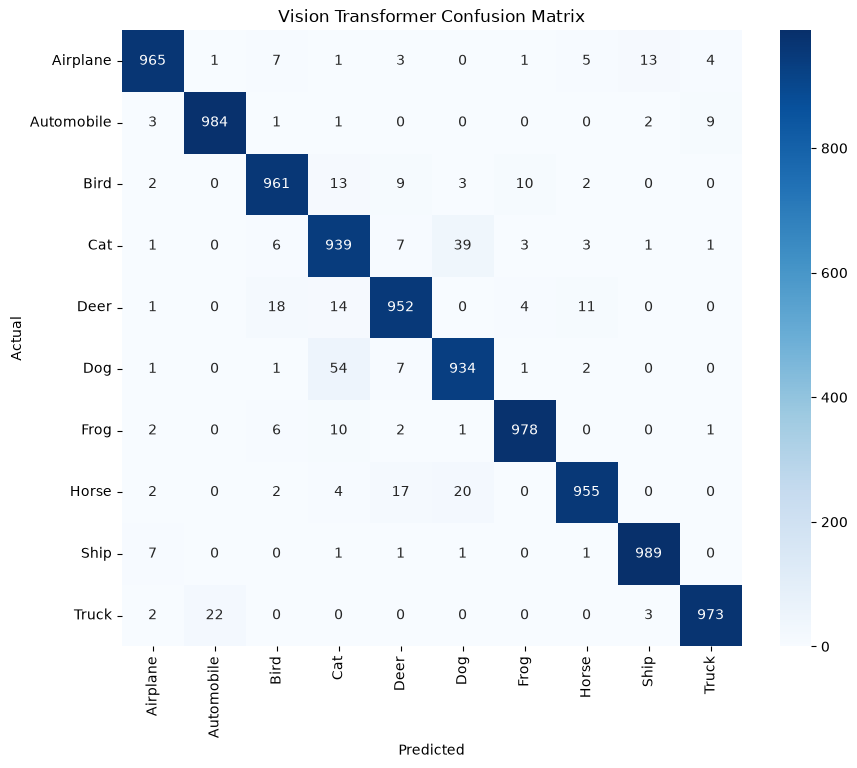

In [54]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Vision Transformer Confusion Matrix")

plt.show()

In [55]:
print(classification_report(
    all_labels,
    all_preds,
    target_names=classes
))

              precision    recall  f1-score   support

    Airplane       0.98      0.96      0.97      1000
  Automobile       0.98      0.98      0.98      1000
        Bird       0.96      0.96      0.96      1000
         Cat       0.91      0.94      0.92      1000
        Deer       0.95      0.95      0.95      1000
         Dog       0.94      0.93      0.93      1000
        Frog       0.98      0.98      0.98      1000
       Horse       0.98      0.95      0.97      1000
        Ship       0.98      0.99      0.99      1000
       Truck       0.98      0.97      0.98      1000

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



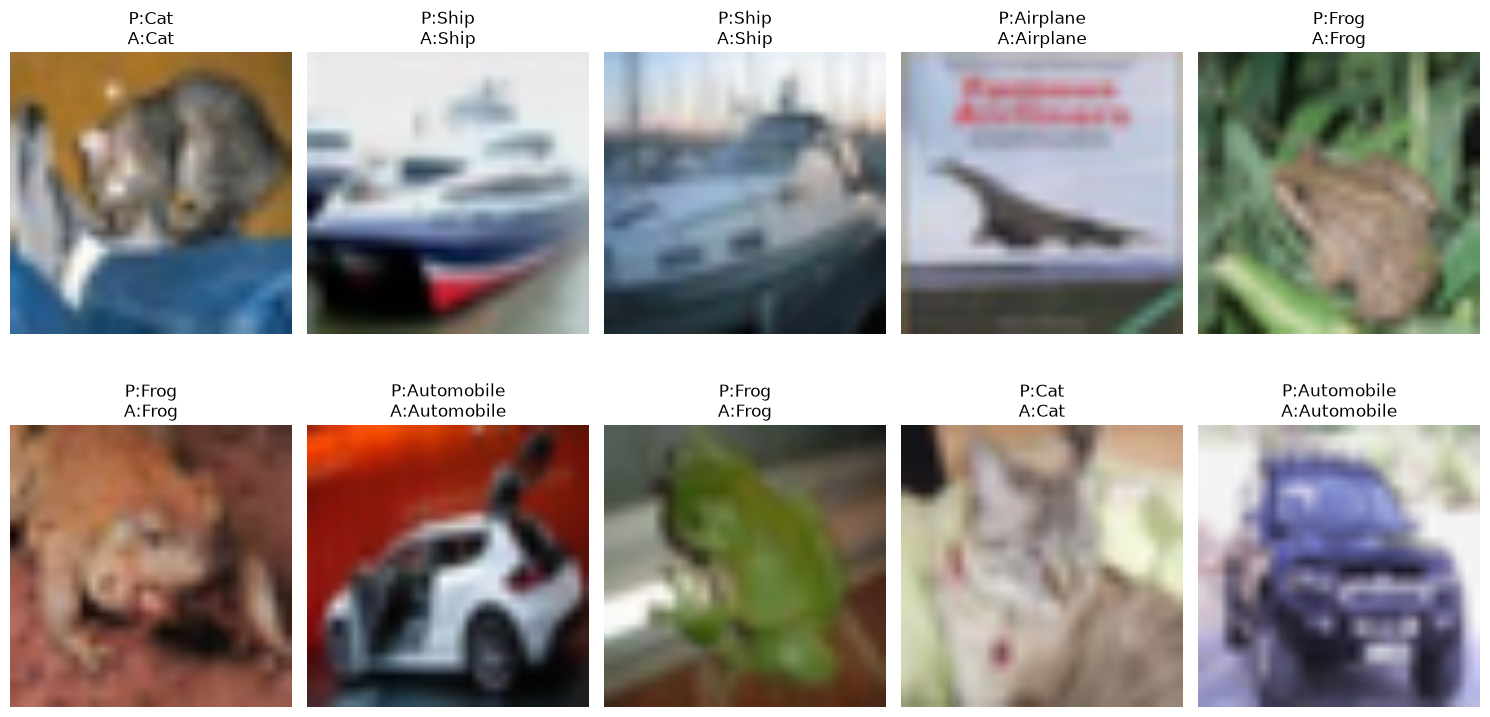

In [56]:
images, labels = next(iter(test_loader))

images_gpu = images.to(device)

with torch.no_grad():

    outputs = model(images_gpu)

    _, predicted = torch.max(outputs,1)

plt.figure(figsize=(15,8))

for i in range(10):

    plt.subplot(2,5,i+1)

    img = images[i].permute(1,2,0).numpy()

    img = img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])

    img = np.clip(img,0,1)

    plt.imshow(img)

    plt.title(
        f"P:{classes[predicted[i].item()]}\nA:{classes[labels[i].item()]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()